# **Prediksi Praktikum 09 (KUNCI JAWABAN) - IF5100 Pemrograman untuk Data Analitik**
## Machine Learning dengan scikit-learn

Nama : ______________________

NIM  : ______________________

### Aturan / Rules

- Kerjakan di **Google Colab** (runtime CPU). Jalankan sel **berurutan** dari atas ke bawah.
- Library: `numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`.
- Gunakan `random_state=42` di **setiap** fungsi yang punya parameter tersebut (`train_test_split`, model, `KFold`, `KMeans`) agar hasil dapat direproduksi.
- **Jangan ubah** nama variabel yang diminta soal dan sel *setup dataset*.
- Setiap grafik wajib punya **judul, label sumbu, dan legend** (jika ada lebih dari satu seri).

| Soal | Topik | Poin |
|---|---|---|
| 1 | Regresi linier dasar & overfitting (data sintetis NumPy) | 20 |
| 2 | Prediksi harga rumah — preprocessing `Pipeline` + `ColumnTransformer` | 30 |
| 3 | Klasifikasi *churn* pelanggan — metrik klasifikasi, KNN, `GridSearchCV` | 30 |
| 4 | Segmentasi pelanggan — `KMeans`, elbow, silhouette | 20 |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_auc_score, RocCurveDisplay, silhouette_score)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

---
## SOAL 1 — Regresi Linier Dasar & Overfitting (20 poin)

### Setup data (jangan diubah)

In [2]:
rng = np.random.default_rng(42)
x = rng.uniform(0, 10, 100)
y = 3 * x + 5 + rng.normal(0, 2, 100)          # hubungan linier + noise

x_poly = np.sort(rng.uniform(-3, 3, 40))
y_poly = 0.5 * x_poly**3 - x_poly**2 - 2 * x_poly + rng.normal(0, 1.5, 40)   # hubungan non-linier

**a.** Ubah `x` menjadi matriks fitur 2D `X` (bentuk `(100, 1)`), lalu bagi menjadi `X_train, X_test, y_train, y_test` dengan proporsi **80:20** dan `random_state=42`. Tampilkan bentuk keempatnya.

*Reshape x into a 2D feature matrix X, split 80:20 with random_state=42, and print the shapes.*

In [3]:
X = x.reshape(-1, 1)          # sklearn butuh X berbentuk 2D: (n_sampel, n_fitur)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(80, 1) (20, 1) (80,) (20,)


**b.** Latih `LinearRegression` sebagai `model_lr`. Tampilkan koefisien (`coef_`) dan intercept (`intercept_`), lalu tuliskan persamaan garisnya. Bandingkan dengan fungsi asli `y = 3x + 5`.

In [4]:
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)
print(f"coef_      = {model_lr.coef_[0]:.4f}")
print(f"intercept_ = {model_lr.intercept_:.4f}")
print(f"Persamaan  : y = {model_lr.coef_[0]:.3f} x + {model_lr.intercept_:.3f}   (asli: y = 3x + 5)")

coef_      = 3.0493
intercept_ = 4.8977
Persamaan  : y = 3.049 x + 4.898   (asli: y = 3x + 5)


**c.** Prediksi `X_test`, lalu hitung **MAE, MSE, RMSE, dan R²** (4 desimal).

In [5]:
y_pred = model_lr.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print(f"MAE  = {mae:.4f}\nMSE  = {mse:.4f}\nRMSE = {rmse:.4f}\nR^2  = {r2:.4f}")

MAE  = 1.4362
MSE  = 3.4350
RMSE = 1.8534
R^2  = 0.9522


**d.** Buat scatter plot data train (biru) dan data test (oranye), beserta garis regresi `model_lr` (merah).

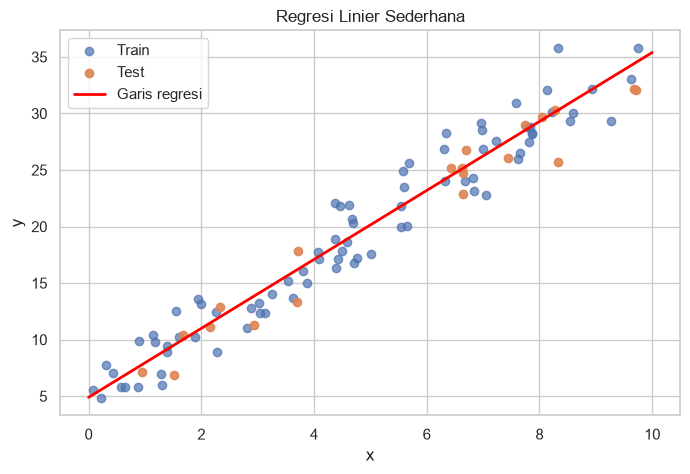

In [6]:
xs = np.linspace(0, 10, 100).reshape(-1, 1)
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, label="Train", alpha=0.7)
plt.scatter(X_test, y_test, label="Test", alpha=0.9)
plt.plot(xs, model_lr.predict(xs), color="red", linewidth=2, label="Garis regresi")
plt.title("Regresi Linier Sederhana")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

**e.** Dengan data `x_poly, y_poly`, bagi 70:30 (`random_state=42`). Untuk derajat polinomial **1, 3, dan 15**, buat pipeline `PolynomialFeatures(degree) → LinearRegression`, hitung **R² train dan R² test**, simpan dalam DataFrame `hasil_poly` (index = derajat). Plot ketiga kurva dalam 1 figure 1×3.

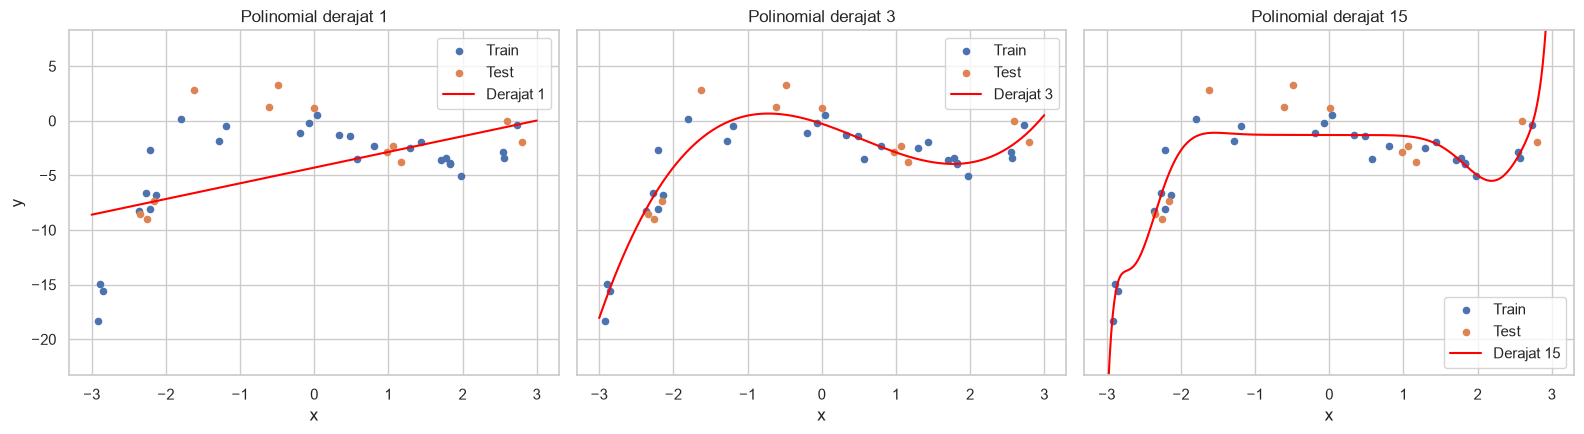

,r2_train,r2_test
derajat,,
1,0.3258,-0.1873
3,0.9220,0.7832
15,0.9378,0.5673


In [7]:
Xp = x_poly.reshape(-1, 1)
Xp_train, Xp_test, yp_train, yp_test = train_test_split(Xp, y_poly, test_size=0.3, random_state=42)

rows = {}
grid = np.linspace(-3, 3, 300).reshape(-1, 1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, deg in zip(axes, [1, 3, 15]):
    pipe = make_pipeline(PolynomialFeatures(degree=deg), LinearRegression())
    pipe.fit(Xp_train, yp_train)
    rows[deg] = {"r2_train": r2_score(yp_train, pipe.predict(Xp_train)),
                 "r2_test": r2_score(yp_test, pipe.predict(Xp_test))}
    ax.scatter(Xp_train, yp_train, s=20, label="Train")
    ax.scatter(Xp_test, yp_test, s=20, label="Test")
    ax.plot(grid, pipe.predict(grid), color="red", label=f"Derajat {deg}")
    ax.set_ylim(y_poly.min() - 5, y_poly.max() + 5)
    ax.set_title(f"Polinomial derajat {deg}")
    ax.set_xlabel("x")
    ax.legend()
axes[0].set_ylabel("y")
plt.tight_layout()
plt.show()

hasil_poly = pd.DataFrame(rows).T.round(4)
hasil_poly.index.name = "derajat"
hasil_poly

**f.** Berdasarkan `hasil_poly`, derajat mana yang mengalami *underfitting*, *good fit*, dan *overfitting*? Jelaskan dengan membandingkan R² train dan R² test.

**Jawaban:**

- **Derajat 1 → underfitting.** Garis lurus tidak mampu mengikuti bentuk kurva kubik, sehingga R² train dan R² test **sama-sama rendah** (model terlalu sederhana / *high bias*).
- **Derajat 3 → good fit.** Bentuk model sama dengan pola data asli (kubik). R² train dan R² test **sama-sama tinggi dan berdekatan**, artinya model bergeneralisasi dengan baik.
- **Derajat 15 → overfitting.** R² train paling tinggi (model "menghafal" noise), tetapi R² test **turun** dibanding derajat 3 dan kurvanya berosilasi liar di ujung-ujung rentang (*high variance*). Selisih besar antara skor train dan test adalah tanda utama overfitting.

---
## SOAL 2 — Prediksi Harga Rumah (30 poin)

Sebuah agen properti ingin memperkirakan **harga rumah (juta rupiah)** dari karakteristiknya. Datanya kotor: ada nilai kosong di kolom numerik dan kategorikal.

| Kolom | Keterangan |
|---|---|
| `id_rumah` | ID unik (bukan fitur) |
| `luas_bangunan` | m² |
| `luas_tanah` | m² (ada NaN) |
| `kamar_tidur` | jumlah kamar |
| `umur_bangunan` | tahun (ada NaN) |
| `jarak_pusat_km` | jarak ke pusat kota |
| `kota` | Jakarta / Bandung / Surabaya (ada NaN) |
| `sertifikat` | SHM / HGB |
| `harga_juta` | **target** |

### Setup dataset (jangan diubah)

In [8]:
def buat_rumah(seed=9, n=600):
    rng = np.random.default_rng(seed)
    lb = rng.uniform(36, 300, n).round()
    lt = (lb * rng.uniform(1.0, 2.0, n)).round()
    kamar = np.clip(np.round(lb / 45 + rng.normal(0, 0.7, n)), 1, 7).astype(int)
    umur = rng.integers(0, 41, n).astype(float)
    jarak = rng.gamma(2.0, 4.0, n).round(1)
    kota = rng.choice(["Jakarta", "Bandung", "Surabaya"], n, p=[0.4, 0.35, 0.25])
    sert = rng.choice(["SHM", "HGB"], n, p=[0.7, 0.3])
    premium = pd.Series({"Jakarta": 900, "Bandung": 300, "Surabaya": 200})[kota].to_numpy()
    harga = (400 + 6 * lb + 2.5 * lt + 60 * kamar - 8 * umur - 25 * jarak + premium
             + np.where(sert == "SHM", 150, 0) + rng.normal(0, 180, n)).round()
    df = pd.DataFrame({"id_rumah": [f"R{i:04d}" for i in range(1, n + 1)],
                       "luas_bangunan": lb, "luas_tanah": lt, "kamar_tidur": kamar,
                       "umur_bangunan": umur, "jarak_pusat_km": jarak, "kota": kota,
                       "sertifikat": sert, "harga_juta": harga})
    for col, frac in [("luas_tanah", 0.05), ("umur_bangunan", 0.03), ("kota", 0.04)]:
        df.loc[rng.choice(n, int(frac * n), replace=False), col] = np.nan
    return df


df_rumah = buat_rumah()
df_rumah.head()

,id_rumah,luas_bangunan,luas_tanah,kamar_tidur,umur_bangunan,jarak_pusat_km,kota,sertifikat,harga_juta
0,R0001,266.0,486.0,6,35.0,5.5,Jakarta,SHM,4097.0
1,R0002,112.0,157.0,2,31.0,12.8,Jakarta,HGB,1907.0
2,R0003,195.0,346.0,6,35.0,3.7,Jakarta,SHM,3500.0
3,R0004,241.0,399.0,5,33.0,4.2,Bandung,SHM,3326.0
4,R0005,225.0,234.0,5,28.0,11.3,Bandung,SHM,2452.0


**a.** Tampilkan ukuran, tipe data, jumlah *missing value* per kolom, dan statistik deskriptif `harga_juta`.

In [9]:
print("Shape:", df_rumah.shape)
print(df_rumah.dtypes, end="\n\n")
print("Missing value:\n", df_rumah.isna().sum(), sep="")
df_rumah["harga_juta"].describe().round(1)

Shape: (600, 9)
id_rumah              str
luas_bangunan     float64
luas_tanah        float64
kamar_tidur         int64
umur_bangunan     float64
jarak_pusat_km    float64
kota                  str
sertifikat            str
harga_juta        float64
dtype: object

Missing value:
id_rumah           0
luas_bangunan      0
luas_tanah        30
kamar_tidur        0
umur_bangunan     18
jarak_pusat_km     0
kota              24
sertifikat         0
harga_juta         0
dtype: int64


count     600.0
mean     2534.3
std       941.3
min       447.0
25%      1817.5
50%      2537.5
75%      3290.2
max      4907.0
Name: harga_juta, dtype: float64

**b.** Pisahkan fitur `X_rumah` (semua kolom kecuali `id_rumah` dan `harga_juta`) dan target `y_rumah`. Bagi 80:20 (`random_state=42`) menjadi `Xr_train, Xr_test, yr_train, yr_test`.

Buat juga list `fitur_numerik` dan `fitur_kategorikal`.

In [10]:
X_rumah = df_rumah.drop(columns=["id_rumah", "harga_juta"])
y_rumah = df_rumah["harga_juta"]

fitur_numerik = X_rumah.select_dtypes(include="number").columns.tolist()
fitur_kategorikal = X_rumah.select_dtypes(exclude="number").columns.tolist()
print("Numerik    :", fitur_numerik)
print("Kategorikal:", fitur_kategorikal)

Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_rumah, y_rumah, test_size=0.2, random_state=42)
print(Xr_train.shape, Xr_test.shape)

Numerik    : ['luas_bangunan', 'luas_tanah', 'kamar_tidur', 'umur_bangunan', 'jarak_pusat_km']
Kategorikal: ['kota', 'sertifikat']
(480, 7) (120, 7)


**c.** Buat `preprocessor` dengan `ColumnTransformer`:
- numerik → `SimpleImputer(strategy="median")` lalu `StandardScaler()`
- kategorikal → `SimpleImputer(strategy="most_frequent")` lalu `OneHotEncoder(handle_unknown="ignore")`

Gabungkan dengan `LinearRegression` dalam `Pipeline` bernama `pipe_lr`, latih di data train, lalu tampilkan **MAE, RMSE, R²** pada data test.

In [11]:
num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler())])
cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("num", num_pipe, fitur_numerik),
                                  ("cat", cat_pipe, fitur_kategorikal)])

pipe_lr = Pipeline([("prep", preprocessor), ("model", LinearRegression())])
pipe_lr.fit(Xr_train, yr_train)


def evaluasi_regresi(model, X_te, y_te):
    pred = model.predict(X_te)
    return {"MAE": mean_absolute_error(y_te, pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_te, pred))),
            "R2": r2_score(y_te, pred)}


eval_lr = evaluasi_regresi(pipe_lr, Xr_test, yr_test)
print({k: round(v, 4) for k, v in eval_lr.items()})

{'MAE': 186.7371, 'RMSE': 249.8279, 'R2': 0.9298}


**d.** Ganti model dengan `RandomForestRegressor(n_estimators=200, random_state=42)` (preprocessor sama) sebagai `pipe_rf`. Buat DataFrame `perbandingan` berisi MAE, RMSE, R² kedua model.

In [12]:
from sklearn.base import clone

pipe_rf = Pipeline([("prep", clone(preprocessor)),
                    ("model", RandomForestRegressor(n_estimators=200, random_state=42))])
pipe_rf.fit(Xr_train, yr_train)

perbandingan = pd.DataFrame({"LinearRegression": eval_lr,
                             "RandomForest": evaluasi_regresi(pipe_rf, Xr_test, yr_test)}).T.round(4)
perbandingan

,MAE,RMSE,R2
LinearRegression,186.7371,249.8279,0.9298
RandomForest,252.6618,325.8095,0.8807


**e.** Lakukan **5-fold cross-validation** (`KFold(n_splits=5, shuffle=True, random_state=42)`, `scoring="r2"`) untuk kedua pipeline pada **seluruh** `X_rumah, y_rumah`. Tampilkan skor tiap fold, rata-rata, dan standar deviasinya.

In [13]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
for nama, pipe in [("LinearRegression", pipe_lr), ("RandomForest", pipe_rf)]:
    skor = cross_val_score(pipe, X_rumah, y_rumah, cv=kf, scoring="r2")
    print(f"{nama:17s} R2 per fold = {np.round(skor, 4)} | mean = {skor.mean():.4f} | std = {skor.std():.4f}")

LinearRegression  R2 per fold = [0.9298 0.9313 0.959  0.9417 0.9349] | mean = 0.9394 | std = 0.0107


RandomForest      R2 per fold = [0.881  0.9114 0.9273 0.9176 0.9121] | mean = 0.9099 | std = 0.0155


**f.** Buat 2 panel: (1) scatter **harga aktual vs prediksi** `pipe_lr` dengan garis y = x; (2) histogram **residual** (aktual − prediksi).

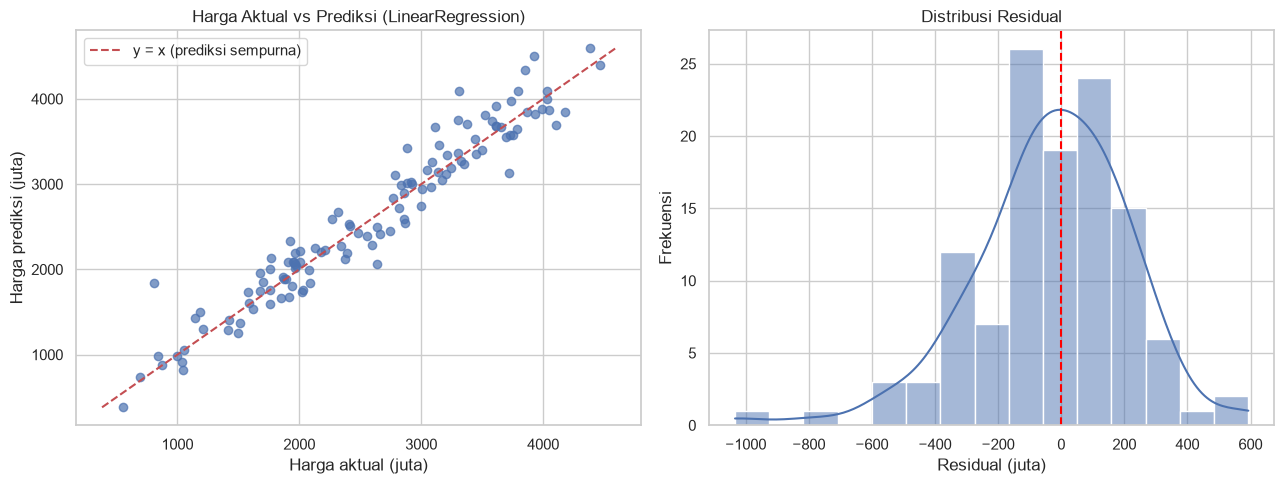

Rata-rata residual: -32.19


In [14]:
pred_lr = pipe_lr.predict(Xr_test)
residual = yr_test - pred_lr

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(yr_test, pred_lr, alpha=0.7)
lim = [min(yr_test.min(), pred_lr.min()), max(yr_test.max(), pred_lr.max())]
axes[0].plot(lim, lim, "r--", label="y = x (prediksi sempurna)")
axes[0].set_title("Harga Aktual vs Prediksi (LinearRegression)")
axes[0].set_xlabel("Harga aktual (juta)")
axes[0].set_ylabel("Harga prediksi (juta)")
axes[0].legend()

sns.histplot(residual, kde=True, ax=axes[1])
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Distribusi Residual")
axes[1].set_xlabel("Residual (juta)")
axes[1].set_ylabel("Frekuensi")
plt.tight_layout()
plt.show()
print("Rata-rata residual:", round(residual.mean(), 2))

**g.** Ambil nama fitur hasil preprocessing (`get_feature_names_out()`) dan koefisien `pipe_lr`. Tampilkan sebagai **horizontal bar chart** terurut. Fitur apa yang paling berpengaruh?

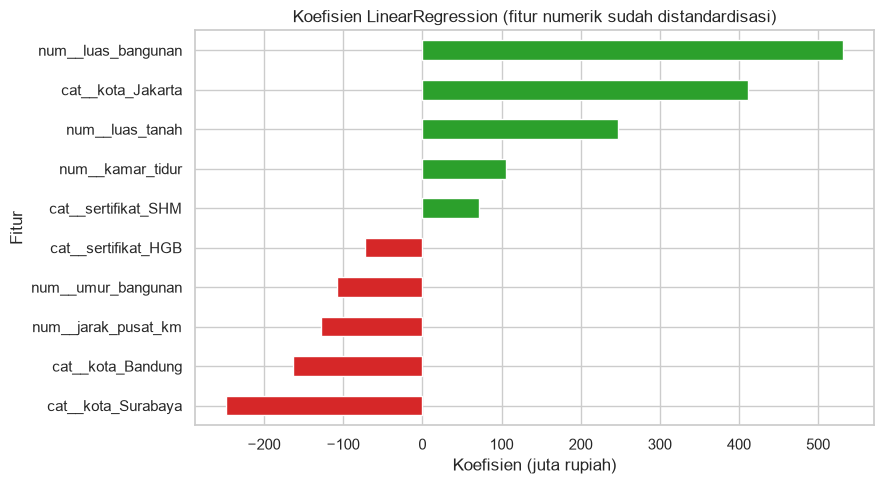

cat__kota_Surabaya    -247.83
cat__kota_Bandung     -163.26
num__jarak_pusat_km   -128.36
num__umur_bangunan    -108.10
cat__sertifikat_HGB    -72.13
cat__sertifikat_SHM     72.13
num__kamar_tidur       105.99
num__luas_tanah        247.48
cat__kota_Jakarta      411.09
num__luas_bangunan     531.65
dtype: float64

In [15]:
nama_fitur = pipe_lr.named_steps["prep"].get_feature_names_out()
koef = pd.Series(pipe_lr.named_steps["model"].coef_, index=nama_fitur).sort_values()

plt.figure(figsize=(9, 5))
koef.plot(kind="barh", color=np.where(koef > 0, "tab:green", "tab:red"))
plt.title("Koefisien LinearRegression (fitur numerik sudah distandardisasi)")
plt.xlabel("Koefisien (juta rupiah)")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()
koef.round(2)

**h.** (i) Mengapa `fit` imputer/scaler hanya boleh dilakukan pada data train? (ii) Model mana yang lebih baik pada soal ini dan mengapa? (iii) Interpretasikan koefisien terbesar pada butir g.

**Jawaban:**

**(i) Data leakage.** Jika imputer/scaler di-`fit` pada seluruh data, median, mean, dan standar deviasi data **test** ikut "bocor" ke proses pelatihan, sehingga skor test menjadi terlalu optimis dan tidak mencerminkan performa pada data baru. Dengan `Pipeline`, `fit` hanya terjadi pada data train, sedangkan data test cukup di-`transform` memakai statistik dari train. Pipeline juga memastikan hal yang sama berlaku di setiap fold cross-validation.

**(ii)** Lihat tabel `perbandingan` dan hasil CV: **LinearRegression** lebih unggul (MAE/RMSE lebih kecil, R² test ±0.93 vs ±0.88; rata-rata R² CV ±0.94 vs ±0.91) dan skornya stabil antar-fold. Ini wajar karena harga pada data ini memang dibentuk dari kombinasi **linier** fitur-fiturnya ditambah noise, jadi model linier sudah sesuai dengan pola data. Random Forest yang lebih kompleks justru kalah karena harus mengaproksimasi hubungan linier dengan potongan-potongan tangga (*step function*), dan dengan 480 data train variansnya lebih besar. Model yang lebih kompleks tidak selalu lebih baik.

**(iii)** Karena fitur numerik sudah distandardisasi, koefisien menunjukkan perubahan harga (juta) untuk kenaikan **1 standar deviasi** fitur, jadi besarnya bisa dibandingkan. `luas_bangunan` dan `luas_tanah` memiliki koefisien positif terbesar (rumah lebih luas → lebih mahal). Untuk fitur one-hot, `kota_Jakarta` jauh lebih tinggi daripada Bandung/Surabaya (premium lokasi) dan `sertifikat_SHM` lebih tinggi daripada HGB. `umur_bangunan` dan `jarak_pusat_km` bernilai negatif: rumah lebih tua dan lebih jauh dari pusat kota cenderung lebih murah.

---
## SOAL 3 — Klasifikasi Churn Pelanggan (30 poin)

Perusahaan internet **NusaNet** ingin memprediksi pelanggan yang akan berhenti berlangganan (*churn*).

| Kolom | Keterangan |
|---|---|
| `lama_langganan` | bulan |
| `biaya_bulanan` | ribu rupiah |
| `jumlah_keluhan` | 3 bulan terakhir |
| `kecepatan_mbps` | paket kecepatan |
| `kontrak` | Bulanan / Tahunan / Dua Tahun |
| `metode_bayar` | Transfer / E-Wallet / Kartu Kredit |
| `churn` | **target** (1 = berhenti, 0 = bertahan) |

### Setup dataset (jangan diubah)

In [16]:
def buat_churn(seed=10, n=1500):
    rng = np.random.default_rng(seed)
    kontrak = rng.choice(["Bulanan", "Tahunan", "Dua Tahun"], n, p=[0.5, 0.3, 0.2])
    lama = np.where(kontrak == "Bulanan", rng.integers(1, 30, n), rng.integers(6, 73, n))
    kecepatan = rng.choice([20, 50, 100, 300], n, p=[0.35, 0.35, 0.2, 0.1])
    biaya = (150 + kecepatan * 0.9 + rng.normal(0, 40, n)).round()
    keluhan = rng.poisson(0.8, n)
    metode = rng.choice(["Transfer", "E-Wallet", "Kartu Kredit"], n, p=[0.4, 0.4, 0.2])
    efek_kontrak = pd.Series({"Bulanan": 0.9, "Tahunan": -0.8, "Dua Tahun": -1.8})[kontrak].to_numpy()
    logit = (-1.6 - 0.04 * lama + 0.006 * (biaya - 200) + 0.75 * keluhan + efek_kontrak
             + np.where(metode == "E-Wallet", 0.3, 0))
    churn = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)
    return pd.DataFrame({"lama_langganan": lama, "biaya_bulanan": biaya, "jumlah_keluhan": keluhan,
                         "kecepatan_mbps": kecepatan, "kontrak": kontrak, "metode_bayar": metode,
                         "churn": churn})


df_churn = buat_churn()
df_churn.head()

,lama_langganan,biaya_bulanan,jumlah_keluhan,kecepatan_mbps,kontrak,metode_bayar,churn
0,26,162.0,1,20,Dua Tahun,E-Wallet,0
1,21,166.0,0,50,Bulanan,Transfer,0
2,43,139.0,0,50,Dua Tahun,E-Wallet,0
3,14,116.0,0,50,Bulanan,Kartu Kredit,0
4,61,195.0,1,100,Tahunan,Transfer,0


**a.** Tampilkan distribusi kelas `churn` (jumlah dan persentase) dan visualisasikan dengan bar chart. Tampilkan juga **churn rate per jenis kontrak**.

       jumlah  persen
churn                
0        1148   76.53
1         352   23.47

Churn rate per kontrak (%):
kontrak
Bulanan      40.26
Tahunan       9.52
Dua Tahun     1.79
Name: churn, dtype: float64


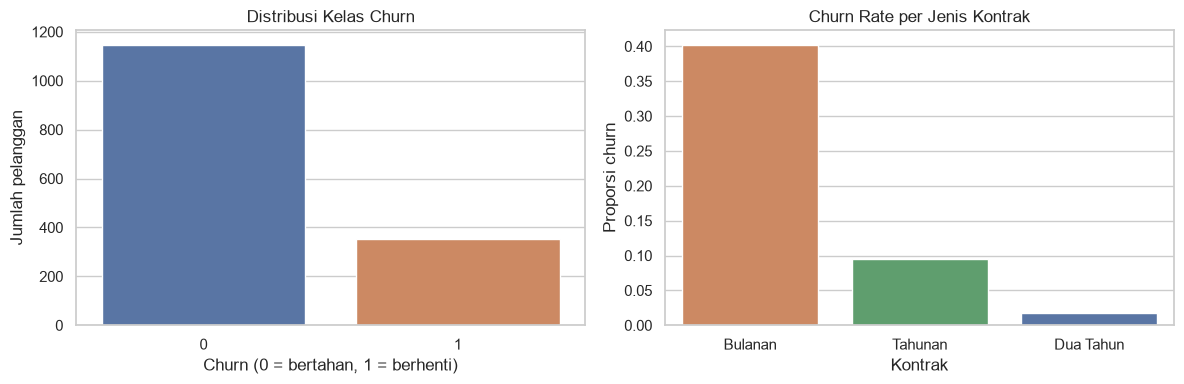

In [17]:
dist = pd.DataFrame({"jumlah": df_churn["churn"].value_counts(),
                     "persen": df_churn["churn"].value_counts(normalize=True).mul(100).round(2)})
print(dist, end="\n\n")
print("Churn rate per kontrak (%):")
print(df_churn.groupby("kontrak")["churn"].mean().mul(100).round(2).sort_values(ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df_churn, x="churn", hue="churn", legend=False, ax=axes[0])
axes[0].set_title("Distribusi Kelas Churn")
axes[0].set_xlabel("Churn (0 = bertahan, 1 = berhenti)")
axes[0].set_ylabel("Jumlah pelanggan")
sns.barplot(data=df_churn, x="kontrak", y="churn", order=["Bulanan", "Tahunan", "Dua Tahun"],
            hue="kontrak", legend=False, errorbar=None, ax=axes[1])
axes[1].set_title("Churn Rate per Jenis Kontrak")
axes[1].set_xlabel("Kontrak")
axes[1].set_ylabel("Proporsi churn")
plt.tight_layout()
plt.show()

**b.** Pisahkan `X_churn`, `y_churn`. Bagi 75:25 dengan **`stratify=y_churn`** dan `random_state=42` menjadi `Xc_train, Xc_test, yc_train, yc_test`. Buktikan proporsi kelas train dan test hampir sama.

In [18]:
X_churn = df_churn.drop(columns="churn")
y_churn = df_churn["churn"]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_churn, y_churn, test_size=0.25, stratify=y_churn, random_state=42)

print("Proporsi churn train:", round(yc_train.mean(), 4))
print("Proporsi churn test :", round(yc_test.mean(), 4))

Proporsi churn train: 0.2347
Proporsi churn test : 0.2347


**c.** Buat `prep_churn` (`StandardScaler` untuk numerik, `OneHotEncoder(handle_unknown="ignore")` untuk kategorikal) dan pipeline `pipe_logreg` dengan `LogisticRegression(max_iter=1000)`. Tampilkan **accuracy, precision, recall, F1** (kelas positif = 1), `classification_report`, dan **confusion matrix** (`ConfusionMatrixDisplay`).

Bandingkan juga dengan **baseline** yang selalu menebak kelas mayoritas (0).

,accuracy,precision,recall,f1
Baseline (selalu 0),0.7653,0.000,0.0000,0.0000
LogisticRegression,0.8027,0.625,0.3977,0.4861


              precision    recall  f1-score   support

Bertahan (0)       0.83      0.93      0.88       287
   Churn (1)       0.62      0.40      0.49        88

    accuracy                           0.80       375
   macro avg       0.73      0.66      0.68       375
weighted avg       0.78      0.80      0.79       375



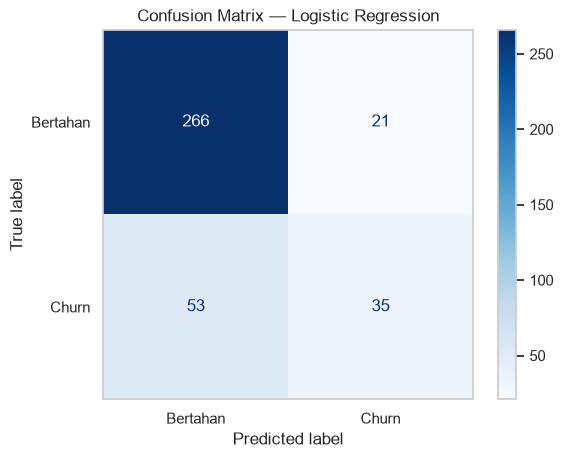

In [19]:
num_churn = ["lama_langganan", "biaya_bulanan", "jumlah_keluhan", "kecepatan_mbps"]
cat_churn = ["kontrak", "metode_bayar"]
prep_churn = ColumnTransformer([("num", StandardScaler(), num_churn),
                                ("cat", OneHotEncoder(handle_unknown="ignore"), cat_churn)])

pipe_logreg = Pipeline([("prep", prep_churn), ("model", LogisticRegression(max_iter=1000))])
pipe_logreg.fit(Xc_train, yc_train)
pred_c = pipe_logreg.predict(Xc_test)


def metrik_klasifikasi(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred),
            "f1": f1_score(y_true, y_pred)}


baseline = np.zeros_like(yc_test)
tabel_metrik = pd.DataFrame({"Baseline (selalu 0)": metrik_klasifikasi(yc_test, baseline),
                             "LogisticRegression": metrik_klasifikasi(yc_test, pred_c)}).T.round(4)
display(tabel_metrik)
print(classification_report(yc_test, pred_c, target_names=["Bertahan (0)", "Churn (1)"]))

ConfusionMatrixDisplay.from_predictions(yc_test, pred_c, display_labels=["Bertahan", "Churn"], cmap="Blues")
plt.title("Confusion Matrix — Logistic Regression")
plt.grid(False)
plt.show()

**d.** Bank ingin menangkap lebih banyak pelanggan churn. Gunakan `predict_proba` dan ubah **threshold** dari 0.5 menjadi **0.3**. Bandingkan precision, recall, dan F1 kedua threshold. Tampilkan juga **ROC curve dan AUC**.

,accuracy,precision,recall,f1
threshold 0.5,0.8027,0.6250,0.3977,0.4861
threshold 0.3,0.7600,0.4915,0.6591,0.5631


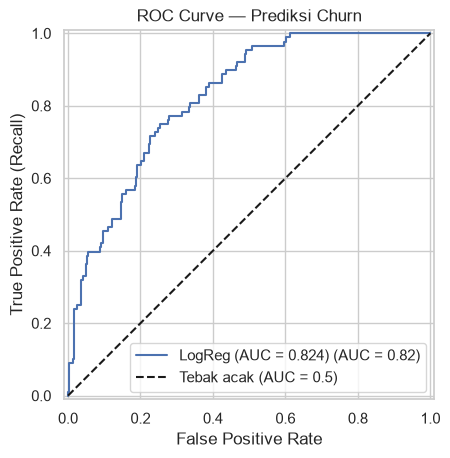

In [20]:
proba = pipe_logreg.predict_proba(Xc_test)[:, 1]
tabel_threshold = pd.DataFrame({f"threshold {t}": metrik_klasifikasi(yc_test, (proba >= t).astype(int))
                                for t in [0.5, 0.3]}).T.round(4)
display(tabel_threshold)

auc = roc_auc_score(yc_test, proba)
RocCurveDisplay.from_predictions(yc_test, proba, name=f"LogReg (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Tebak acak (AUC = 0.5)")
plt.title("ROC Curve — Prediksi Churn")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.legend()
plt.show()

**e.** Latih `KNeighborsClassifier` untuk **k = 1, 3, 5, …, 29**, **dengan** dan **tanpa** scaling (tanpa scaling: fitur numerik dipakai apa adanya, kategorikal tetap di-one-hot). Plot **F1 test** terhadap k untuk kedua versi dalam satu grafik.

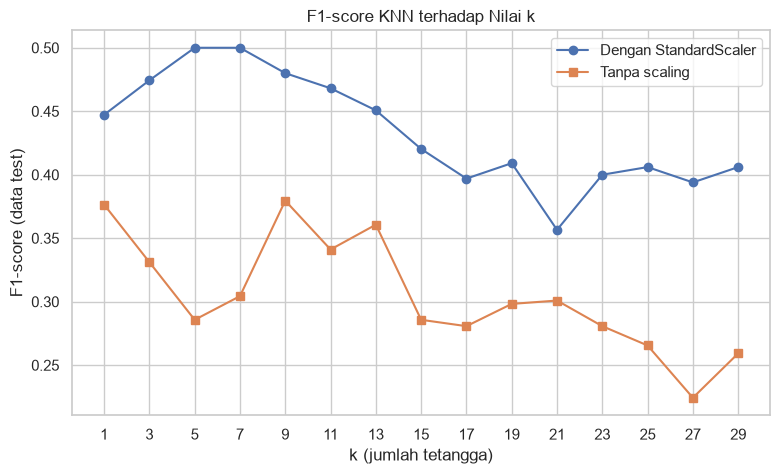

k terbaik (dengan scaling) = 5, F1 = 0.5000
F1 terbaik tanpa scaling     = 0.3796


In [21]:
ks = list(range(1, 30, 2))
prep_noscale = ColumnTransformer([("num", "passthrough", num_churn),
                                  ("cat", OneHotEncoder(handle_unknown="ignore"), cat_churn)])
f1_scaled, f1_raw = [], []
for k in ks:
    for prep, wadah in [(prep_churn, f1_scaled), (prep_noscale, f1_raw)]:
        pipe = Pipeline([("prep", clone(prep)), ("model", KNeighborsClassifier(n_neighbors=k))])
        pipe.fit(Xc_train, yc_train)
        wadah.append(f1_score(yc_test, pipe.predict(Xc_test)))

plt.figure(figsize=(9, 5))
plt.plot(ks, f1_scaled, marker="o", label="Dengan StandardScaler")
plt.plot(ks, f1_raw, marker="s", label="Tanpa scaling")
plt.xticks(ks)
plt.title("F1-score KNN terhadap Nilai k")
plt.xlabel("k (jumlah tetangga)")
plt.ylabel("F1-score (data test)")
plt.legend()
plt.show()

best_k = ks[int(np.argmax(f1_scaled))]
print(f"k terbaik (dengan scaling) = {best_k}, F1 = {max(f1_scaled):.4f}")
print(f"F1 terbaik tanpa scaling     = {max(f1_raw):.4f}")

**f.** Gunakan `GridSearchCV` (5-fold `StratifiedKFold`, `scoring="f1"`) untuk mencari `max_depth` ∈ {2, 3, 4, 5, 6, 8, 10, 15} dan `min_samples_leaf` ∈ {1, 5, 10, 20} pada `DecisionTreeClassifier(random_state=42)` (dengan `prep_churn`). Tampilkan parameter terbaik, skor CV terbaik, dan F1 di data test.

In [22]:
pipe_tree = Pipeline([("prep", clone(prep_churn)), ("model", DecisionTreeClassifier(random_state=42))])
param_grid = {"model__max_depth": [2, 3, 4, 5, 6, 8, 10, 15],
              "model__min_samples_leaf": [1, 5, 10, 20]}
grid_tree = GridSearchCV(pipe_tree, param_grid, scoring="f1",
                         cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42))
grid_tree.fit(Xc_train, yc_train)

print("Parameter terbaik :", grid_tree.best_params_)
print("F1 CV terbaik     :", round(grid_tree.best_score_, 4))
print("F1 data test      :", round(f1_score(yc_test, grid_tree.predict(Xc_test)), 4))

hasil_grid = pd.DataFrame(grid_tree.cv_results_).pivot_table(
    index="param_model__max_depth", columns="param_model__min_samples_leaf", values="mean_test_score")
hasil_grid.round(3)

Parameter terbaik : {'model__max_depth': 15, 'model__min_samples_leaf': 5}
F1 CV terbaik     : 0.5018
F1 data test      : 0.4774


param_model__min_samples_leaf,1,5,10,20
param_model__max_depth,,,,
2,0.408,0.408,0.408,0.408
3,0.426,0.427,0.429,0.442
4,0.390,0.400,0.396,0.397
5,0.457,0.461,0.480,0.431
6,0.454,0.455,0.450,0.449
8,0.465,0.500,0.480,0.435
10,0.439,0.486,0.470,0.435
15,0.456,0.502,0.473,0.435


**g.** (i) Mengapa accuracy saja menyesatkan pada data ini? (ii) Untuk kasus churn, mana yang lebih penting: precision atau recall? Kaitkan dengan hasil butir d. (iii) Mengapa KNN sangat terpengaruh scaling?

**Jawaban:**

**(i)** Kelas tidak seimbang: sebagian besar pelanggan tidak churn. Baseline yang **selalu menebak 0** sudah mendapat accuracy tinggi (sebesar proporsi kelas 0), padahal recall-nya 0, sehingga tidak ada satu pun pelanggan churn yang tertangkap. Karena itu perlu dilihat precision, recall, F1, confusion matrix, atau AUC.

**(ii)** Umumnya **recall** lebih penting: biaya kehilangan pelanggan (*false negative*) jauh lebih besar daripada biaya memberi promo retensi kepada pelanggan yang sebenarnya tidak akan pergi (*false positive*). Pada butir d, menurunkan threshold ke 0.3 **menaikkan recall** (lebih banyak pelanggan churn tertangkap) dengan konsekuensi **precision turun**. Ini *trade-off* precision–recall; threshold dipilih sesuai biaya bisnis, bukan selalu 0.5. AUC menunjukkan kemampuan model membedakan kedua kelas di semua threshold.

**(iii)** KNN menghitung **jarak Euclidean**. Tanpa scaling, fitur berskala besar (`biaya_bulanan` ratusan, `kecepatan_mbps` hingga 300) mendominasi jarak, sedangkan fitur penting berskala kecil (`jumlah_keluhan` 0–5, one-hot 0/1) hampir diabaikan. `StandardScaler` membuat semua fitur bermean 0 dan berstandar deviasi 1 sehingga kontribusinya setara; grafik butir e memperlihatkan F1 versi dengan scaling lebih tinggi di hampir semua k. k kecil (mis. 1) cenderung overfitting, sedangkan k terlalu besar cenderung underfitting.

---
## SOAL 4 — Segmentasi Pelanggan dengan K-Means (20 poin)

Sebuah mal ingin mengelompokkan pengunjung berdasarkan perilaku belanja (tanpa label → *unsupervised learning*).

### Setup dataset (jangan diubah)

In [23]:
def buat_mall(seed=11):
    rng = np.random.default_rng(seed)
    pusat = {"pendapatan_juta": [8, 25, 25, 60, 60], "skor_belanja": [20, 50, 85, 15, 80],
             "umur": [45, 38, 24, 42, 30], "kunjungan_bulanan": [2, 4, 9, 2, 7]}
    sebaran = {"pendapatan_juta": 4, "skor_belanja": 7, "umur": 8, "kunjungan_bulanan": 1.2}
    ukuran = [60, 80, 50, 50, 60]
    blok = []
    for i, n in enumerate(ukuran):
        blok.append(pd.DataFrame({c: rng.normal(pusat[c][i], sebaran[c], n) for c in pusat}))
    df = pd.concat(blok, ignore_index=True).sample(frac=1, random_state=seed).reset_index(drop=True)
    df["pendapatan_juta"] = df["pendapatan_juta"].clip(3).round(1)
    df["skor_belanja"] = df["skor_belanja"].clip(1, 100).round()
    df["umur"] = df["umur"].clip(17, 70).round()
    df["kunjungan_bulanan"] = df["kunjungan_bulanan"].clip(0).round()
    df.insert(0, "id_pelanggan", [f"C{i:03d}" for i in range(1, len(df) + 1)])
    return df


df_mall = buat_mall()
df_mall.head()

,id_pelanggan,pendapatan_juta,skor_belanja,umur,kunjungan_bulanan
0,C001,34.2,82.0,24.0,8.0
1,C002,26.1,50.0,47.0,3.0
2,C003,20.2,30.0,37.0,3.0
3,C004,57.2,17.0,45.0,3.0
4,C005,10.7,19.0,51.0,4.0


**a.** Ambil fitur `pendapatan_juta, skor_belanja, umur, kunjungan_bulanan`, standardisasi dengan `StandardScaler` menjadi `X_mall_scaled`. Tampilkan mean dan std tiap kolom setelah scaling.

In [24]:
fitur_mall = ["pendapatan_juta", "skor_belanja", "umur", "kunjungan_bulanan"]
scaler_mall = StandardScaler()
X_mall_scaled = scaler_mall.fit_transform(df_mall[fitur_mall])
print(pd.DataFrame(X_mall_scaled, columns=fitur_mall).agg(["mean", "std"]).round(3))

      pendapatan_juta  skor_belanja   umur  kunjungan_bulanan
mean            0.000         0.000 -0.000             -0.000
std             1.002         1.002  1.002              1.002


**b.** Untuk k = 2 sampai 10, latih `KMeans(n_clusters=k, n_init=10, random_state=42)`, simpan **inertia** dan **silhouette score**. Plot keduanya dalam figure 1×2 (*elbow method* & silhouette). Tentukan `k_terbaik`.

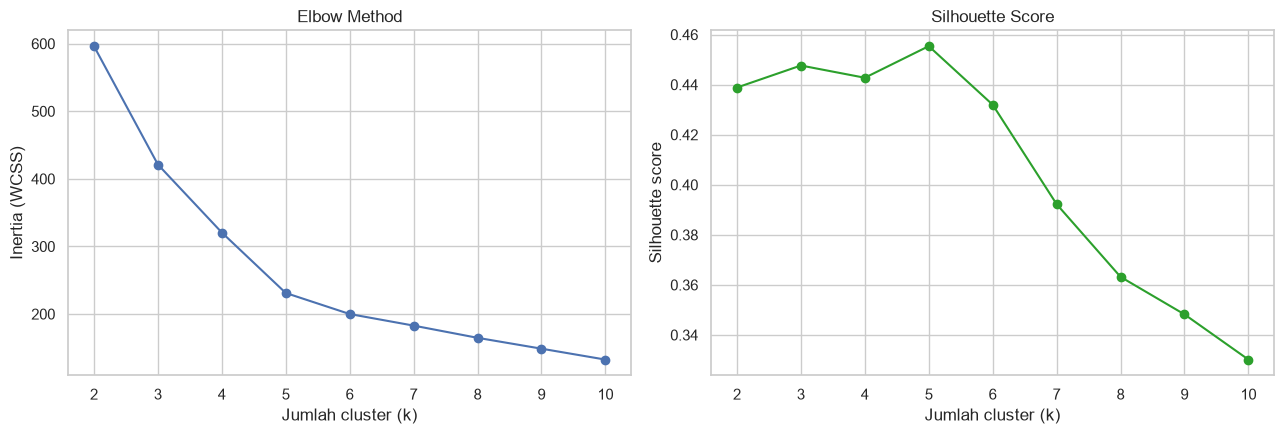

 k  inertia  silhouette
 2    596.3      0.4388
 3    421.2      0.4476
 4    320.5      0.4427
 5    231.1      0.4554
 6    200.0      0.4320
 7    182.8      0.3922
 8    164.8      0.3632
 9    148.7      0.3482
10    132.5      0.3301
k_terbaik = 5


In [25]:
k_range = range(2, 11)
inertia, silhouette = [], []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_mall_scaled)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_mall_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(list(k_range), inertia, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Jumlah cluster (k)")
axes[0].set_ylabel("Inertia (WCSS)")
axes[1].plot(list(k_range), silhouette, marker="o", color="tab:green")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Jumlah cluster (k)")
axes[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.show()

k_terbaik = list(k_range)[int(np.argmax(silhouette))]
print(pd.DataFrame({"k": list(k_range), "inertia": np.round(inertia, 1),
                    "silhouette": np.round(silhouette, 4)}).to_string(index=False))
print("k_terbaik =", k_terbaik)

**c.** Latih KMeans final dengan `k_terbaik`, simpan label ke kolom `cluster` di `df_mall`. Buat **profil cluster**: rata-rata tiap fitur dan jumlah anggota per cluster.

In [26]:
kmeans_final = KMeans(n_clusters=k_terbaik, n_init=10, random_state=42)
df_mall["cluster"] = kmeans_final.fit_predict(X_mall_scaled)

profil = df_mall.groupby("cluster")[fitur_mall].mean().round(1)
profil["jumlah"] = df_mall["cluster"].value_counts().sort_index()
profil

,pendapatan_juta,skor_belanja,umur,kunjungan_bulanan,jumlah
cluster,,,,,
0,59.0,16.1,44.1,2.0,50
1,24.7,84.2,24.8,8.9,50
2,8.4,22.3,46.2,1.9,62
3,59.0,80.6,31.3,6.9,60
4,25.4,50.8,37.7,4.0,78


**d.** Visualisasikan hasil clustering: (1) scatter `pendapatan_juta` vs `skor_belanja` diwarnai cluster, beserta **centroid** (kembalikan ke skala asli dengan `scaler_mall.inverse_transform`); (2) scatter 2 komponen utama **PCA** diwarnai cluster.

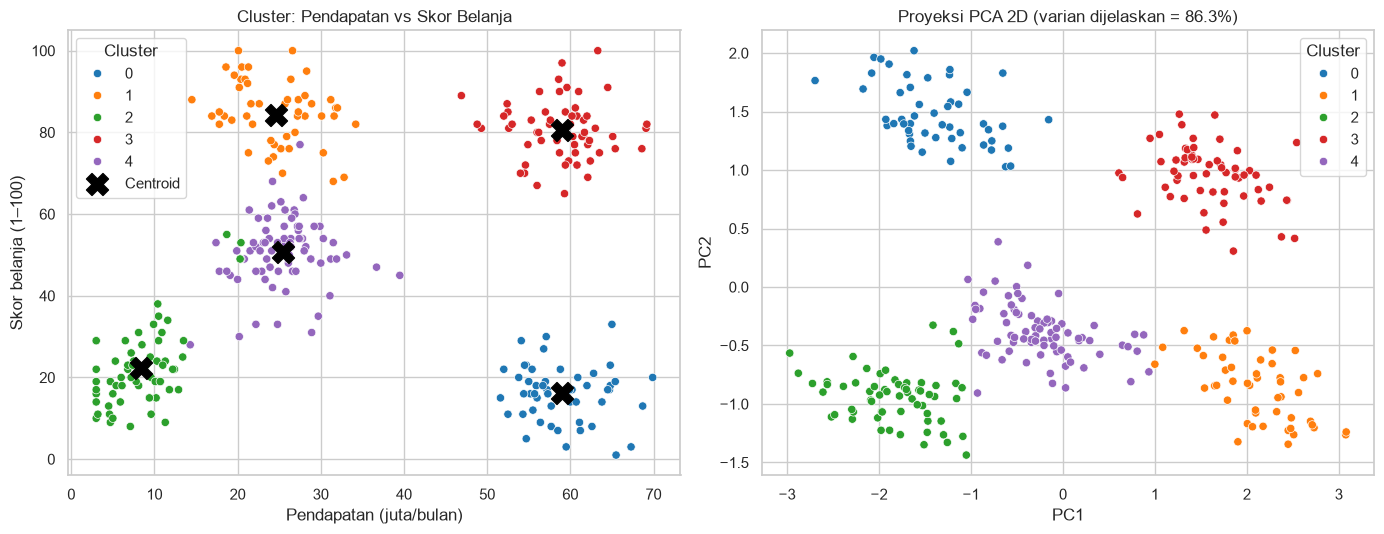

In [27]:
centroid = pd.DataFrame(scaler_mall.inverse_transform(kmeans_final.cluster_centers_), columns=fitur_mall)
pca = PCA(n_components=2, random_state=42)
komponen = pca.fit_transform(X_mall_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(data=df_mall, x="pendapatan_juta", y="skor_belanja", hue="cluster",
                palette="tab10", ax=axes[0])
axes[0].scatter(centroid["pendapatan_juta"], centroid["skor_belanja"], marker="X", s=250,
                color="black", label="Centroid")
axes[0].set_title("Cluster: Pendapatan vs Skor Belanja")
axes[0].set_xlabel("Pendapatan (juta/bulan)")
axes[0].set_ylabel("Skor belanja (1–100)")
axes[0].legend(title="Cluster")

sns.scatterplot(x=komponen[:, 0], y=komponen[:, 1], hue=df_mall["cluster"], palette="tab10", ax=axes[1])
axes[1].set_title(f"Proyeksi PCA 2D (varian dijelaskan = {pca.explained_variance_ratio_.sum():.1%})")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].legend(title="Cluster")
plt.tight_layout()
plt.show()

**e.** Beri nama tiap segmen berdasarkan profilnya dan satu rekomendasi strategi pemasaran. Mengapa data harus distandardisasi sebelum K-Means?

**Jawaban:**

Berdasarkan tabel `profil` (nomor cluster bisa berbeda, cocokkan dengan rata-ratanya), terbentuk **5 segmen**:

| Profil | Nama segmen | Strategi |
|---|---|---|
| Pendapatan rendah (±8 jt), skor belanja rendah, umur ±45 | **Hemat** | Promo diskon & paket harga terjangkau |
| Pendapatan menengah (±25 jt), skor sedang | **Standar** | Program poin loyalitas untuk mendorong frekuensi |
| Pendapatan menengah, skor sangat tinggi, muda (±24), sering datang | **Impulsif Muda** | Promo media sosial, event, *flash sale* |
| Pendapatan tinggi (±60 jt), skor rendah | **Kaya Hati-hati** | Penawaran eksklusif/berkualitas untuk mengubah potensi menjadi belanja |
| Pendapatan tinggi, skor tinggi, sering datang | **Pelanggan Premium/VIP** | Layanan VIP, *early access* produk baru |

**Mengapa distandardisasi?** K-Means meminimalkan jarak Euclidean ke centroid. Tanpa scaling, fitur dengan rentang besar (`skor_belanja` 1–100, `pendapatan_juta` 3–75) akan mendominasi jarak dibanding `kunjungan_bulanan` (0–12), sehingga cluster hanya ditentukan oleh fitur berskala besar. Setelah standardisasi, setiap fitur berkontribusi setara. Pemilihan k terbaik memakai elbow (titik tekuk inertia) dan silhouette tertinggi, yang keduanya menunjuk ke k = 5.

---
## Soal Teori

### 1. Apa beda *supervised* dan *unsupervised learning*? Beri contoh masing-masing dari praktikum ini.

**Jawaban:**

*Supervised*: data memiliki label/target yang diketahui, dan model belajar memetakan fitur → target. Contohnya regresi harga rumah (Soal 2, target kontinu) dan klasifikasi churn (Soal 3, target kategorikal). *Unsupervised*: tidak ada label, dan model mencari struktur/pola sendiri, misalnya segmentasi pelanggan dengan K-Means (Soal 4) atau reduksi dimensi dengan PCA.

### 2. Jelaskan perbedaan `fit`, `transform`, `fit_transform`, dan `predict`.

**Jawaban:**

`fit` mempelajari parameter dari data (mean/std pada scaler, koefisien pada model). `transform` menerapkan parameter yang sudah dipelajari ke data. `fit_transform` menggabungkan keduanya, dan **hanya dipakai pada data train**. `predict` menghasilkan prediksi dari model yang sudah di-`fit`. Pada data test cukup memanggil `transform`/`predict`, tidak boleh `fit` ulang, karena itu menyebabkan *data leakage*.

### 3. Apa itu *data leakage*? Sebutkan 2 contohnya.

**Jawaban:**

Kebocoran informasi dari data test (atau informasi yang tidak tersedia saat prediksi) ke proses training, sehingga evaluasi terlalu optimis. Contoh: (1) melakukan scaling/imputasi pada seluruh data sebelum `train_test_split`; (2) memakai fitur yang baru diketahui setelah kejadian, misalnya kolom "tanggal_berhenti" untuk memprediksi churn; (3) melakukan seleksi fitur dengan melihat seluruh data. Solusinya adalah split terlebih dahulu lalu memakai `Pipeline`.

### 4. Mengapa perlu `stratify` saat `train_test_split` pada klasifikasi?

**Jawaban:**

Agar proporsi tiap kelas di train dan test sama dengan data asli. Pada data tidak seimbang, split acak biasa bisa menghasilkan test set dengan proporsi kelas minoritas yang terlalu sedikit atau terlalu banyak, sehingga evaluasi tidak representatif. `StratifiedKFold` menerapkan prinsip yang sama pada cross-validation.

### 5. Apa fungsi *cross-validation* dibanding satu kali train-test split?

**Jawaban:**

Satu kali split hasilnya bergantung pada keberuntungan pembagian data. K-fold CV melatih dan menguji model k kali pada lipatan yang berbeda, lalu merata-ratakan skornya. Hasilnya estimasi performa yang lebih stabil, ditambah ukuran variasinya (std), dan semua data sempat dipakai sebagai data uji. CV juga dipakai `GridSearchCV` untuk memilih hyperparameter tanpa menyentuh test set.

### 6. Jelaskan *bias–variance trade-off* dan kaitannya dengan underfitting/overfitting.

**Jawaban:**

Bias tinggi berarti model terlalu sederhana dan gagal menangkap pola (underfitting: skor train dan test sama-sama rendah). Variance tinggi berarti model terlalu kompleks dan sensitif terhadap noise data train (overfitting: skor train tinggi, test rendah). Menambah kompleksitas menurunkan bias tetapi menaikkan variance; model terbaik berada di titik keseimbangan, seperti polinomial derajat 3 pada Soal 1e, `max_depth` optimal pada Soal 3f, atau k sedang pada KNN.

### 7. Kapan memakai MAE vs RMSE? Apa arti R² = 0 dan R² negatif?

**Jawaban:**

MAE adalah rata-rata kesalahan absolut, mudah diinterpretasikan, dan tidak terlalu sensitif terhadap outlier. RMSE menghukum kesalahan besar lebih berat (karena dikuadratkan), sehingga dipakai bila kesalahan besar sangat merugikan. Keduanya bersatuan sama dengan target. R² = 0 berarti model tidak lebih baik daripada selalu menebak rata-rata target; R² negatif berarti model **lebih buruk** daripada tebakan rata-rata, misalnya karena overfitting parah.

### 8. Mengapa `OneHotEncoder` lebih tepat daripada `LabelEncoder` untuk fitur nominal seperti `kota`?

**Jawaban:**

`LabelEncoder` mengubah kategori menjadi 0, 1, 2 sehingga model (terutama model linier/berbasis jarak) mengira ada urutan dan jarak (Surabaya > Jakarta > Bandung), padahal kota bersifat nominal. One-hot membuat satu kolom biner per kategori tanpa urutan palsu. `handle_unknown="ignore"` mencegah error ketika data test berisi kategori yang tidak ada di data train. Untuk data ordinal (mis. S/M/L) bisa dipakai `OrdinalEncoder` dengan urutan yang ditentukan.